In [54]:
import pandas as pd
from zoneinfo import ZoneInfo
from datetime import datetime as dt, timezone
import holidays
import seaborn as sns
import json

In [59]:
stations_df = pd.read_csv('citibike-stations.csv')
id_to_shortname = dict(zip(stations_df['station_id'], stations_df['short_name']))
id_to_lat = dict(zip(stations_df['station_id'], stations_df['lat']))
id_to_lon = dict(zip(stations_df['station_id'], stations_df['lon']))
id_to_name = dict(zip(stations_df['station_id'], stations_df['name']))
shortname_to_name = dict(zip(stations_df['short_name'], stations_df['name']))

In [61]:
used_shortname_to_name = {name: shortname_to_name[name] for name in df['shortname'].unique()}
used_shortname_to_name 

{'3978.13': 'Garfield Pl & 8 Ave',
 '4488.08': 'Court St & State St',
 '5532.01': 'Mercer St & Spring St',
 '5279.03': 'Centre St & Worth St',
 '6737.03': '36 Ave & 10 St',
 '4965.01': 'Lorimer St & Broadway',
 'JC084': 'Communipaw & Berry Lane',
 'JC057': 'Riverview Park',
 '7538.12': 'Central Park West & W 100 St',
 '6215.04': 'W 25 St & 6 Ave',
 '6650.07': 'E 55 St & 2 Ave',
 '5785.05': 'Greenpoint Ave & Manhattan Ave',
 '7634.01': 'W 106 St & Amsterdam Ave',
 '4322.02': 'Dean St & 4 Ave',
 '3996.04': '2 Ave & 9 St',
 'JC056': 'Sip Ave',
 '4266.03': 'Clinton St & Union St',
 '6729.02': '21 St & 36 Ave',
 'JC013': 'Marin Light Rail',
 '4962.01': 'Broadway & Battery Pl',
 '6806.06': '35 Ave & 10 St',
 '4846.01': 'South St & Whitehall St',
 '6030.04': 'W 13 St & 7 Ave',
 'JC099': 'Montgomery St',
 '6879.04': '28 Ave & 44 St',
 '5288.08': 'Park Pl & Church St'}

## Data Processing again bru

In [64]:
df = pd.read_csv('medium_train_set.csv')

### Final Pipeline

In [43]:
def process_file(csv_file):
    df = pd.read_csv(csv_file)

    df['timestamp'] = pd.to_datetime(df['station_status_last_reported'], format="%Y-%m-%d %H:%M:%S%z", utc=True)
    df = df.drop('station_status_last_reported', axis=1)

    df['Month'] = df['timestamp'].dt.month
    df['Day'] = df['timestamp'].dt.dayofweek
    df['Hour'] = df['timestamp'].dt.hour
    df['IsWeekend'] = df['Day'].isin([5,6]).astype(int)
    df['lat'] = df['station_id'].map(id_to_lat)
    df['lon'] = df['station_id'].map(id_to_lon)
    df['percentage_available'] = df['num_bikes_available'] / (df['num_bikes_available'] + df['num_docks_available'])
    df['IsRushHour'] = ((df['Hour'].isin([7,8,9,16,17,18])) & (df['IsWeekend'] == 0)).astype(int)
    df['shortname'] = df['station_id'].map(id_to_shortname)


    ny_holidays = holidays.US(state='NY')
    holiday_date_list = list(ny_holidays.keys())

    df['IsHoliday'] = df['timestamp'].dt.date.isin(holiday_date_list).astype(int)
    df['IsNonWorkingDay'] = ((df['IsWeekend'] == 1) | (df['IsHoliday'] == 1)).astype(int)

    # lag features

    df = df.sort_values('timestamp').reset_index(drop=True)
    df['prev_percentage'] = df.groupby('station_id')['percentage_available'].shift(1)
    df['time_since_last_lag'] = df.groupby('station_id')['timestamp'].diff().dt.total_seconds() / 60
    df['time_since_last_lag'] = df['time_since_last_lag'].clip(upper=1440)
    df['time_since_last_lag'] = df['time_since_last_lag'].fillna(0)

    cols = ['shortname', 'Month', 'Day', 'Hour', 
                   'IsWeekend', 'IsHoliday', 'IsNonWorkingDay', 'lat', 'lon', 'prev_percentage', 'time_since_last_lag', 'IsRushHour','timestamp']

    print(f"Before dropping NA: {df.shape[0]} rows")
    df = df[cols + ['percentage_available']].dropna()
    print(f"After dropping NA: {df.shape[0]} rows")
    df['shortname'] = df['shortname'].astype('category')

    

    return df
    

## Baseline XgBoost

In [5]:
# Import necessary libraries for time series modeling
import numpy as np
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from catboost import CatBoostRegressor


In [66]:
df = process_file('medium_train_set.csv')
feature_columns = ['shortname', 'Month', 'Day', 'Hour', 
                   'IsWeekend', 'IsHoliday', 'IsNonWorkingDay', 'lat', 'lon', 'prev_percentage', 'time_since_last_lag', 'IsRushHour']


X_train = df[feature_columns]
y_train = df['percentage_available']

Before dropping NA: 533614 rows
After dropping NA: 533408 rows


In [68]:
val_dataset = process_file('medium_crossval_set.csv')
X_val = val_dataset[feature_columns]
y_val = val_dataset['percentage_available']

Before dropping NA: 426500 rows
After dropping NA: 425933 rows


### Base Line Model Training

In [69]:
# Train baseline XGBoost model
print("Training baseline XGBoost model...")

# Initialize XGBoost regressor with default parameters
baseline_model = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.1,
    depth=6,
    loss_function='RMSE',
    eval_metric='RMSE',
    random_seed=42,
    verbose=100
)

baseline_model.fit(X_train, y_train, cat_features=['shortname'], eval_set=(X_val, y_val))

y_train_pred = baseline_model.predict(X_train)
y_val_pred = baseline_model.predict(X_val)

train_mae = mean_absolute_error(y_train, y_train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_r2 = r2_score(y_train, y_train_pred)

val_mae = mean_absolute_error(y_val, y_val_pred)
val_rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
val_r2 = r2_score(y_val, y_val_pred)

print("\n=== Baseline Model Performance ===")
print(f"\nTraining Set:")
print(f"  MAE:  {train_mae:.4f}")
print(f"  RMSE: {train_rmse:.4f}")
print(f"  R²:   {train_r2:.4f}")

print(f"\nValidation Set:")
print(f"  MAE:  {val_mae:.4f}")
print(f"  RMSE: {val_rmse:.4f}")
print(f"  R²:   {val_r2:.4f}")

Training baseline XGBoost model...
0:	learn: 0.2767731	test: 0.2928766	best: 0.2928766 (0)	total: 212ms	remaining: 3m 32s
100:	learn: 0.0510127	test: 0.0611501	best: 0.0611501 (100)	total: 16.1s	remaining: 2m 23s
200:	learn: 0.0488183	test: 0.0595602	best: 0.0595602 (200)	total: 31.6s	remaining: 2m 5s
300:	learn: 0.0476032	test: 0.0588428	best: 0.0588390 (298)	total: 45.6s	remaining: 1m 45s
400:	learn: 0.0468712	test: 0.0584406	best: 0.0584388 (397)	total: 58.7s	remaining: 1m 27s
500:	learn: 0.0463339	test: 0.0582961	best: 0.0582961 (500)	total: 1m 13s	remaining: 1m 13s
600:	learn: 0.0458108	test: 0.0580465	best: 0.0580465 (600)	total: 1m 27s	remaining: 58.1s
700:	learn: 0.0453704	test: 0.0578971	best: 0.0578961 (698)	total: 1m 40s	remaining: 43.1s
800:	learn: 0.0450127	test: 0.0577757	best: 0.0577757 (800)	total: 1m 54s	remaining: 28.3s
900:	learn: 0.0446562	test: 0.0576810	best: 0.0576807 (890)	total: 2m 8s	remaining: 14.1s
999:	learn: 0.0443844	test: 0.0576458	best: 0.0576447 (995)	

### Baseline model graph

<Axes: xlabel='timestamp', ylabel='predictions'>

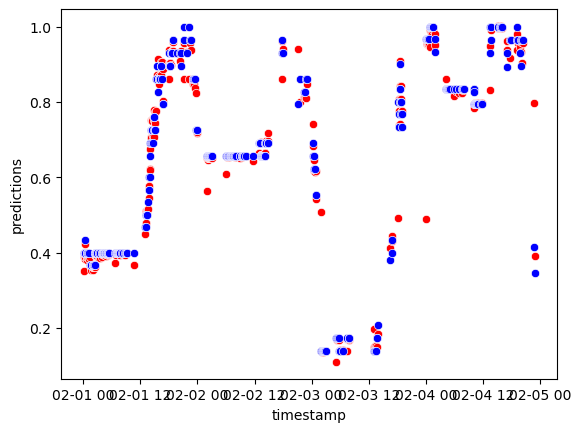

In [70]:
val_dataset['predictions'] = y_val_pred

timeframe_graphed = (val_dataset['timestamp'] >= dt(2019,2,1, tzinfo = timezone.utc)) & (val_dataset['timestamp'] < dt(2019,2,5, tzinfo = timezone.utc))

sns.scatterplot(data= val_dataset[(val_dataset['shortname'] == '5532.01') & timeframe_graphed], x='timestamp', y='predictions', color = 'red')
sns.scatterplot(data= val_dataset[(val_dataset['shortname'] == '5532.01') & timeframe_graphed], x='timestamp', y='percentage_available', color = 'blue')


In [48]:
val_dataset['shortname'].unique()

['7634.01', 'JC084', '5279.03', '6030.04', '5288.08', ..., 'JC099', '4488.08', '4266.03', '3996.04', '4962.01']
Length: 26
Categories (26, object): ['3978.13', '3996.04', '4266.03', '4322.02', ..., 'JC056', 'JC057', 'JC084', 'JC099']

### Time Series Cross Validation Setup

In [ ]:
df_full = process_file('train_set.csv')
feature_columns = ['shortname', 'Month', 'Day', 'Hour', 
                   'IsWeekend', 'IsHoliday', 'IsNonWorkingDay', 'lat', 'lon', 'prev_percentage', 'time_since_last_lag', 'IsRushHour']
X = df_full[feature_columns]
y = df_full['percentage_available']

In [ ]:
tscv = TimeSeriesSplit(n_splits=5)

# Store results for each fold
cv_results = {
    'fold': [],
    'train_mae': [],
    'train_rmse': [],
    'train_r2': [],
    'val_mae': [],
    'val_rmse': [],
    'val_r2': []
}

# Perform cross-validation
for fold_idx, (train_idx, val_idx) in enumerate(tscv.split(X), 1):
    print(f"\nFold {fold_idx}:")
    print(f"  Train size: {len(train_idx)}, Validation size: {len(val_idx)}")
    
    # Split data for this fold
    X_train_fold = X.iloc[train_idx]
    X_val_fold = X.iloc[val_idx]
    y_train_fold = y.iloc[train_idx]
    y_val_fold = y.iloc[val_idx]
    
    # Train model
    model = CatBoostRegressor(
        iterations=1000,
        learning_rate=0.1,
        depth=6,
        loss_function='RMSE',
        eval_metric='RMSE',
        random_seed=42,
        verbose=100
        
    )
    model.fit(X_train_fold, y_train_fold)
    
    # Predictions
    y_train_pred_fold = model.predict(X_train_fold)
    y_val_pred_fold = model.predict(X_val_fold)
    
    # Calculate metrics
    train_mae_fold = mean_absolute_error(y_train_fold, y_train_pred_fold)
    train_rmse_fold = np.sqrt(mean_squared_error(y_train_fold, y_train_pred_fold))
    train_r2_fold = r2_score(y_train_fold, y_train_pred_fold)
    
    val_mae_fold = mean_absolute_error(y_val_fold, y_val_pred_fold)
    val_rmse_fold = np.sqrt(mean_squared_error(y_val_fold, y_val_pred_fold))
    val_r2_fold = r2_score(y_val_fold, y_val_pred_fold)
    
    # Store results
    cv_results['fold'].append(fold_idx)
    cv_results['train_mae'].append(train_mae_fold)
    cv_results['train_rmse'].append(train_rmse_fold)
    cv_results['train_r2'].append(train_r2_fold)
    cv_results['val_mae'].append(val_mae_fold)
    cv_results['val_rmse'].append(val_rmse_fold)
    cv_results['val_r2'].append(val_r2_fold)
    
    print(f"  Validation MAE:  {val_mae_fold:.4f}")
    print(f"  Validation RMSE: {val_rmse_fold:.4f}")
    print(f"  Validation R²:   {val_r2_fold:.4f}")

# Calculate average metrics across all folds
print("\n" + "="*50)
print("Cross-Validation Summary")
print("="*50)
print(f"\nAverage Training Metrics:")
print(f"  MAE:  {np.mean(cv_results['train_mae']):.4f} (+/- {np.std(cv_results['train_mae']):.4f})")
print(f"  RMSE: {np.mean(cv_results['train_rmse']):.4f} (+/- {np.std(cv_results['train_rmse']):.4f})")
print(f"  R²:   {np.mean(cv_results['train_r2']):.4f} (+/- {np.std(cv_results['train_r2']):.4f})")

print(f"\nAverage Validation Metrics:")
print(f"  MAE:  {np.mean(cv_results['val_mae']):.4f} (+/- {np.std(cv_results['val_mae']):.4f})")
print(f"  RMSE: {np.mean(cv_results['val_rmse']):.4f} (+/- {np.std(cv_results['val_rmse']):.4f})")
print(f"  R²:   {np.mean(cv_results['val_r2']):.4f} (+/- {np.std(cv_results['val_r2']):.4f})")